In [104]:
import os
if 'SunStatistics' not in os.getcwd():
    os.chdir('../SunStatistics')
import SolarCalc as SC

sc=SC.System(
    Timestamp=['2024-01-01T00:00:00','2026-12-31T23:59:59','30min'],
    Latitude=69.229178,
    Longitude=-135.257278,
    transmissivity=0.6,
    UTC=True,
    Slope=62.5,
    Full_Load_Watts=24,
    Discharge_Limit=0.55,
    Batt_Sequences_in_Parallel=12
    )


In [105]:
import numpy as np
import pandas as pd
import statsmodels.api as sm
import matplotlib.pyplot as plt


def sp(x=1,y=1,kwargs={}):
    return(plt.subplots(x,y,**kwargs))

def quick_filter(
        filename,
        cols,
        ch4_sig = 20,
        irgason_sig = .85,
        qc_thresh = 1,
        u_thresh = .1,
        plot=False,
        q_clip=True
        ):
    df = pd.read_csv(filename,header=[0],skiprows=[0,2],na_values=[-9999])
    df.index = pd.to_datetime(df['date']+' '+df['time'])
    # print(df.columns[df.columns.str.contains('v')])
    # Filter wind dir
    df.loc[((df['wind_dir']>35+180-30)&(df['wind_dir']<35+180+30)),['co2_flux','ch4_flux','LE','H']]=np.nan
    # Filter u*
    df.loc[((df['u*']<u_thresh)),['co2_flux','ch4_flux','LE','H']]=np.nan
    # Other QC
    for f in  ['H','LE','co2_flux','ch4_flux']:
        df.loc[df[f'qc_{f}'].fillna(qc_thresh+1)>=qc_thresh,f]=np.nan
        if f == 'LE':
            if 'h2o_signal_mean' in df.columns:
                df.loc[(df['h2o_signal_mean']<=irgason_sig),'LE']=np.nan
            else:
                df.loc[(df['mean_value_AGC_LI-7500']<=irgason_sig),'LE']=np.nan
        elif f == 'co2_flux':
            if 'co2_signal_mean' in df.columns:
                df.loc[(df[f'co2_signal_mean']>=irgason_sig*100),f]=np.nan
            else:
                df.loc[(df[f'mean_value_AGC_LI-7500']>=irgason_sig*100),f]=np.nan
        elif f == 'ch4_flux':
            if 'ch4_signal_mean' in df.columns:
                df.loc[(df[f'ch4_signal_mean']<=ch4_sig),f]=np.nan
            else:
                df.loc[(df[f'diag_77_mean']<=ch4_sig),f]=np.nan
    df.loc[((df['LE'].isna())|(df['H'].isna())),['co2_flux','ch4_flux']] = np.nan
    # df.loc[(df['x_peak'].isna()),['H','LE','co2_flux','ch4_flux']] = np.nan
    if plot:
        fig,ax=sp(4,kwargs={'sharex':True,'figsize':(10,10)})
        df['ch4_flux'].plot(ax=ax[0],ylabel='umol m-2 s-1',title='FCH4',grid=True)
        df['co2_flux'].plot(ax=ax[1],ylabel='umol m-2 s-1',title='FCO2',grid=True)
        df['LE'].plot(ax=ax[2],ylabel='W m-2',title='LE',grid=True)
        df['H'].plot(ax=ax[3],ylabel='W m-2',title='H',grid=True)
        fig.autofmt_xdate()
        plt.tight_layout()
    s = df['wind_dir'].copy()
    s[s>33+180]-=360
    s.name='wd'
    df = df[[c for c in cols if c in df.columns]].join(s)
    # df = df.join(s)
    df['air_pressure']*=0.001
    if q_clip:
        # cx = ['co2_flux','ch4_flux','LE','H']
        for m in df.index.month.unique():
            for c in ['co2_flux','ch4_flux','LE','H']:
                df.loc[((df.index.month == m) & (df[c]>df.loc[df.index.month==m,c].quantile(.99))),c]=np.nan
                df.loc[((df.index.month == m) & (df[c]<df.loc[df.index.month==m,c].quantile(.01))),c]=np.nan
    df.index = df.index.tz_localize('UTC')
    return(df)
    

In [106]:
filename = r"D:\data-dump\SCL\corrected\recalc\eddypro_corrected_v4_full_output_2026-06-14T195313_exp.csv"

cols = ['wind_dir','wind_speed','u*','sonic_temperature',
        'H','qc_H','LE','qc_LE','h2o_signal_mean',
        'co2_flux','qc_co2_flux','co2_signal_mean','co2_mixing_ratio',
        'ch4_flux','qc_ch4_flux','ch4_signal_mean','ch4_mole_fraction',
        'x_peak','air_temperature','air_pressure','x_30%','v_var','daytime']
cols = [c for c in cols if 'qc' not in c]
kwagrs={
    'ch4_sig':20,
    'irgason_sig':.8,
    'qc_thresh':1,
    'u_thresh':.1,
    'plot':False,
    # 'q_clip':False
}

filename = [
    r"D:\data-dump\SCL\EddyPro\2024\eddypro_t_full_output_2025-05-02T224906_exp.csv",
    r"D:\data-dump\SCL\corrected\recalc\eddypro_corrected_v4_full_output_2026-06-14T195313_exp.csv",
    r"D:\data-dump\SCL\EddyPro\eddypro_corrected_v5_2606_full_output_2026-10-08T153810_exp.csv",
    r"D:\data-dump\SCL\EddyPro\eddypro_corrected_v5_260708_full_output_2026-10-08T161521_exp.csv",
    r"D:\data-dump\SCL\EddyPro\eddypro_corrected_v5_2609_full_output_2026-10-08T162421_exp.csv"
    ]



drange = pd.DataFrame(index=sc.UTC_Time,data={'Solar_elevation':sc.Solar_elevation,'SW_IN_max':sc.SW_in,'Solar_time':sc.Solar_Time})
df = pd.concat([quick_filter(fn, cols, **kwagrs) for fn in filename])


df = df.loc[~df.index.duplicated(keep='first')].resample('30min').asfreq()
df = pd.concat([drange,df],axis=1).sort_index()
df.loc[((df.index.month==4)&(df['co2_flux']<0)),'co2_flux']=0
df['ch4_flux'] *= 1e3
df[['H','LE','co2_flux','ch4_flux']].groupby([df.index.month]).agg(['mean','std','count'])
# df.loc[df.index.month==5,'H'].dropna()#


H                          LE                   co2_flux  \
         mean        std count       mean        std count      mean   
1         NaN        NaN     0        NaN        NaN     0       NaN   
2         NaN        NaN     0        NaN        NaN     0       NaN   
3         NaN        NaN     0        NaN        NaN     0       NaN   
4    2.232084  12.260570   226   3.605353   3.234668   224  0.039797   
5    7.546736  17.468708   807        NaN        NaN     0       NaN   
6   38.851413  56.137490   868  43.877818  37.750697   587 -0.267468   
7   42.262656  56.847516  1324  65.769248  46.326809  1261 -3.014454   
8   22.762799  44.604105  2903  46.146582  37.796814  2756 -2.340156   
9    5.708348  32.471920  2349  23.825902  18.133606  2078 -0.021898   
10  -7.820142  16.413071   708  14.060821  10.007653   539  0.173013   
11 -10.659992   9.164438   837   2.862372   4.288245   176  0.025988   
12  -7.615082  13.124896   170        NaN        NaN     0       NaN   

                     ch4_flux                   
         std count       mean        std count  
1        NaN     0        NaN        NaN     0  
2        NaN     0        NaN        NaN     0  
3        NaN     0        NaN        NaN     0  
4   0.051911   171  10.603353  10.385802   153  
5        NaN     0        NaN        NaN     0  
6   0.862749   485  33.444908  25.123649   321  
7   2.739509  1071  64.598445  46.031469   956  
8   2.759975  2302  56.686456  29.678465  2133  
9   0.948028  1597  26.849995  20.609483  1154  
10  0.302312   391        NaN        NaN     0  
11  0.324664   139        NaN        NaN     0  
12       NaN     0        NaN        NaN     0

co2_flux
0.7982299657945272
ch4_flux
0.5821089377545913


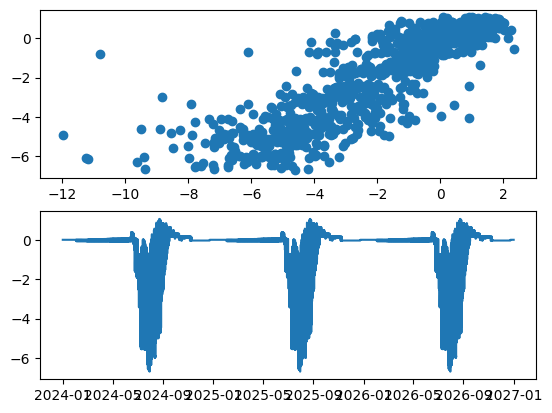

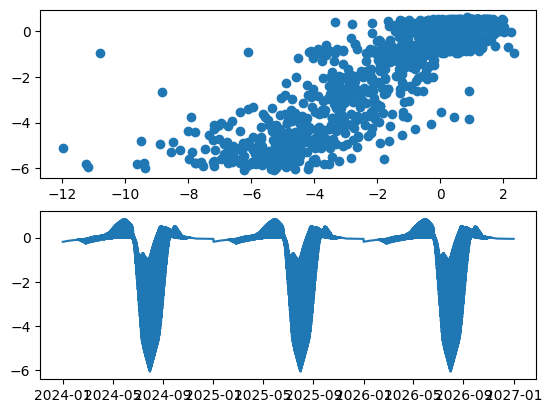

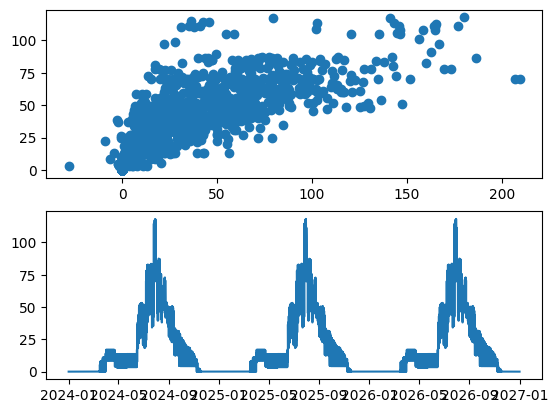

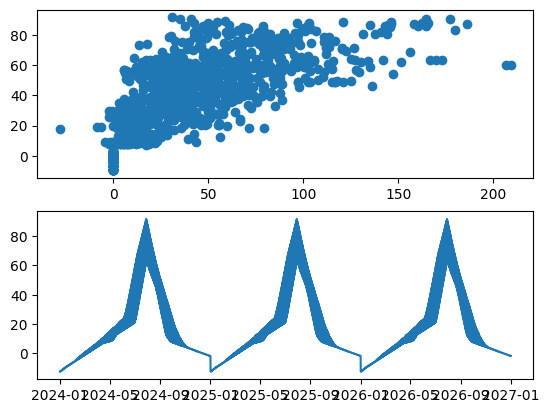

In [108]:
# # df.loc[df.index.month == 4,'ch4_flux'].plot()
# df[['air_temperature','sonic_temperature']].plot()
# df[['ch4_flux','air_temperature']].corr()
# import statsmodels.api as sm
from sklearn.ensemble import RandomForestRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

x = ['air_temperature','air_pressure','wind_speed','wind_dir','x_peak','DOY','HR','daytime']
df['DOY'] = df.index.dayofyear
df['HR'] = df.index.hour
df['Month'] = df.index.month
df['Year'] = df.index.year
# df['GS'] = 0
# df.loc[df.index.month == 7,'GS']=1
# df.loc[df.index.month == 8,'GS']=1
# df.loc[df.index.month == 6,'GS']=1
x = ['DOY','SW_IN_max']
# X = ['Solar_elevation','SW_IN_max','Solar_time','DOY']

bfx = 5

for DOYxz in [350,365,15,30,45,60,75]:
    df.loc[df.index.dayofyear==DOYxz,'co2_flux'] = df.loc[(df.index.month==4),'co2_flux'].median()*np.random.rand(len(df.loc[df.index.dayofyear==DOYxz,'co2_flux']))*1e-4
    df.loc[df.index.dayofyear==DOYxz,'ch4_flux'] = df.loc[(df.index.month==4),'ch4_flux'].quantile(.5)*np.random.rand(len(df.loc[df.index.dayofyear==DOYxz,'co2_flux']))*1e-4
    # print(df.loc[(df.index.month==4),'ch4_flux'].quantile(.5))

# for c in ['ch4_flux']:
#     df.loc[(df.index.dayofyear<=0+bfx)|(df.index.dayofyear>=366-bfx),c] = df.loc[((df.index.month==4)|(df.index.month==11)),c].median()

for y in ['co2_flux','ch4_flux']:
    print(y)
    T = df[[y]+x].dropna()
    Y = T[y].copy()
    X = T[x].copy()
    X_train, X_test, y_train, y_test = train_test_split(X, Y, test_size=0.2, random_state=42)

    rf = RandomForestRegressor(min_samples_leaf=30, random_state=0)
    m = rf.fit(X_train, y_train)
    print(m.score(X_test, y_test))
    fig,ax=plt.subplots(2)
    ax[0].scatter(y_test,m.predict(X_test))
    # HR = np.array([[D,H] for D in range(1,366) for H in range(24)])
    df[f"rf_{y}"] = np.nan
    df.loc[df[x].notna().all(axis=1), f"rf_{y}"] = m.predict(df[x].dropna())
    ax[1].plot(df.index,df[f"rf_{y}"])

    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)
    mlp = MLPRegressor(hidden_layer_sizes=(100, 50), activation='relu', max_iter=500, random_state=42)
    mlp.fit(X_train_scaled, y_train)
    mlp.score(X_test_scaled, y_test)

    fig,ax=plt.subplots(2)
    ax[0].scatter(y_test,mlp.predict(X_test_scaled))
    # predictions = mlp.predict(scaler.transform(df[x].dropna()))
    df[f"mlp_{y}"] = np.nan
    df.loc[df[x].notna().all(axis=1), f"mlp_{y}"] = mlp.predict(scaler.transform(df[x].dropna()))
    ax[1].plot(df.index,df[f"mlp_{y}"])


,co2,ch4
mean,-486.277974,4.956942
std,1781.341825,9.053781
count,52608.000000,52608.000000
CI,43.491934,0.221050


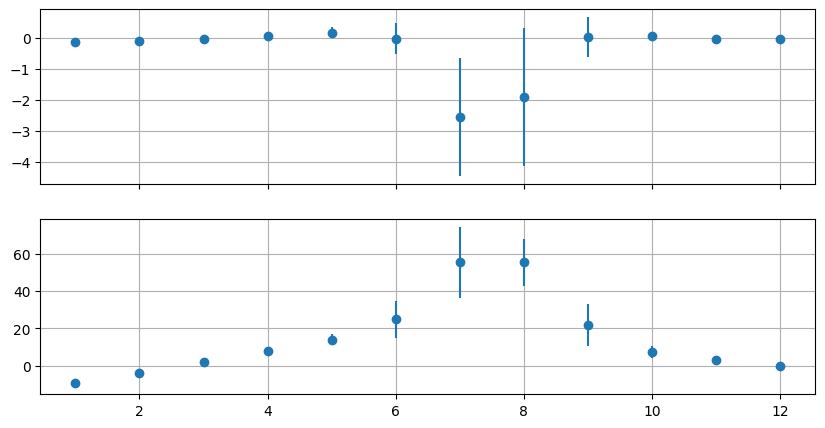

In [155]:
dfx = df[['co2_flux','rf_co2_flux','mlp_co2_flux','ch4_flux','rf_ch4_flux','mlp_ch4_flux']].groupby([df.index.month]).agg(['mean','std','count'])
# dfx[[('mlp_co2_flux','mean'),('mlp_ch4_flux','mean')]].plot(subplots=True,figsize=(10,5),grid=True,yerr=dfx[[('mlp_co2_flux','std'),('mlp_ch4_flux','std')]]
figa,ax=plt.subplots(2,1,figsize=(10,5),sharex=True)
ax[0].errorbar(dfx.index,dfx[('mlp_co2_flux','mean')],yerr=dfx[('mlp_co2_flux','std')],label='MLP',fmt='o')
ax[1].errorbar(dfx.index,dfx[('mlp_ch4_flux','mean')],yerr=dfx[('mlp_ch4_flux','std')],label='MLP',fmt='o')
ax[0].grid(True)
ax[1].grid(True)
# mx = df[['co2_flux','ch4_flux']].fillna((df[['mlp_co2_flux','mlp_ch4_flux']]+df[['rf_co2_flux','rf_ch4_flux']])/2).agg(['mean','std','count']).T

df['co2'] = df['co2_flux'].fillna(df[['rf_co2_flux','mlp_co2_flux']].mean(axis=1))* 44.01*1e-6*3600*24*356#*1e3/3600
df['ch4'] = df['co2_flux'].fillna(df[['rf_ch4_flux','mlp_ch4_flux']].mean(axis=1))* 16.04*1e-9*3600*24*356#*1e3/3600
mo = [i for i in range(1,13)]
# mo = [4,5,6,7,8,9,10,11]
mx = df.loc[df.index.month.isin(mo),['co2','ch4']].agg(['mean','std','count'])
mx = mx.T
mx['CI'] = 1.96*mx['std']/np.sqrt(df[['ch4_flux','co2_flux']].count().mean())
mx = mx.T
# mx = mx[['mean','CI']].T
# mx['co2'] *= 44.01*1e-6*3600*24*365#*1e3/3600
# mx['ch4'] *= 16.04*1e-9*3600*24*365*83#*1e3/3600
mx
# mx[['co2_flux','ch4_flux']].sum(axis=1)
# dfx


In [118]:
df[['ch4_flux','ch4']].mean()

ch4_flux    39.478022
ch4         -0.181711
dtype: float64

In [ ]:
# plt.figure()
# plt.scatter(df['DOY'],df['mlp_co2_flux'])
# plt.scatter(df['DOY'],df['co2_flux'])
# df[['co2_flux','ch4_flux']].mean()

,co2,ch4
mean,-719.891479,-21.777003
std,2201.145096,66.585514


993
Background
0.06969407779526067 0.04028543340249961
Seep-affected(300-20/60-75)
1.3024860385532995 0.17557084294970166
Seep-center (20-60)
13.217291175141245 0.9923548204601805


<Axes: xlabel='Wind Direction (deg)', ylabel='FCH4 umol m-2 s-1'>

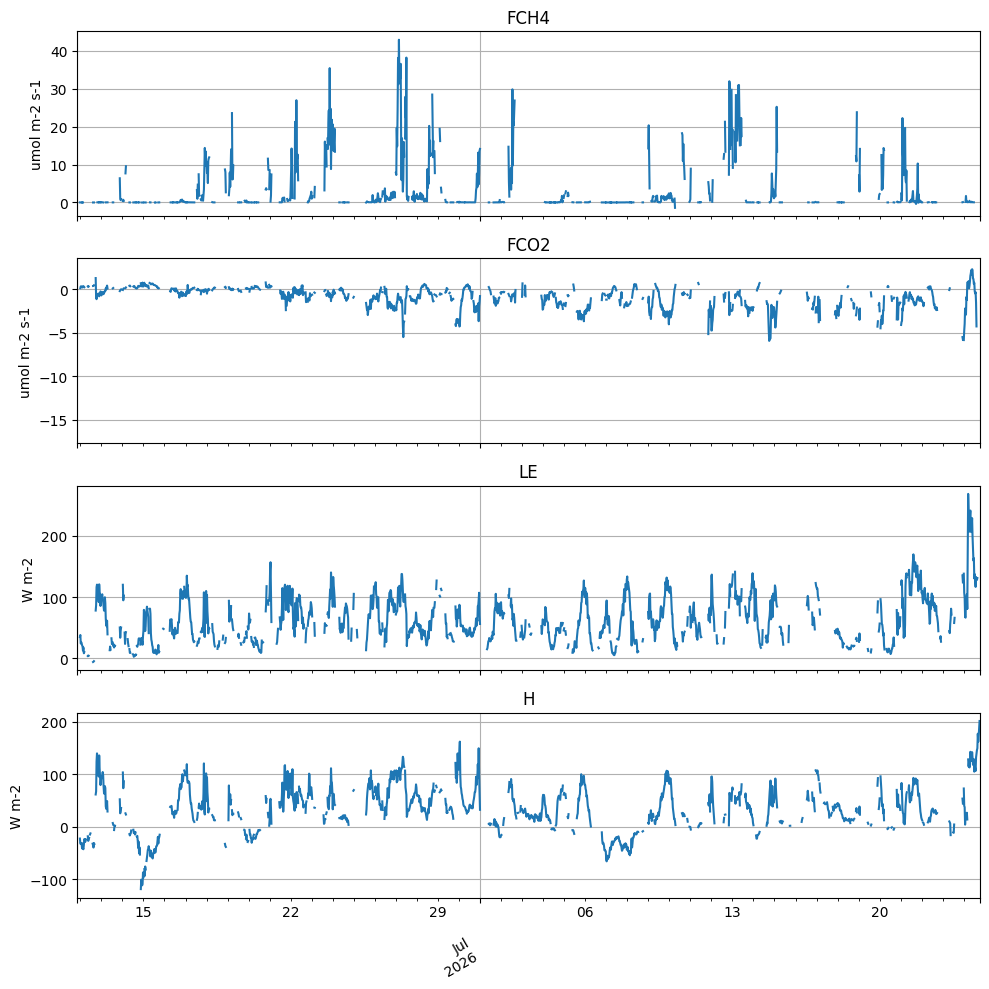

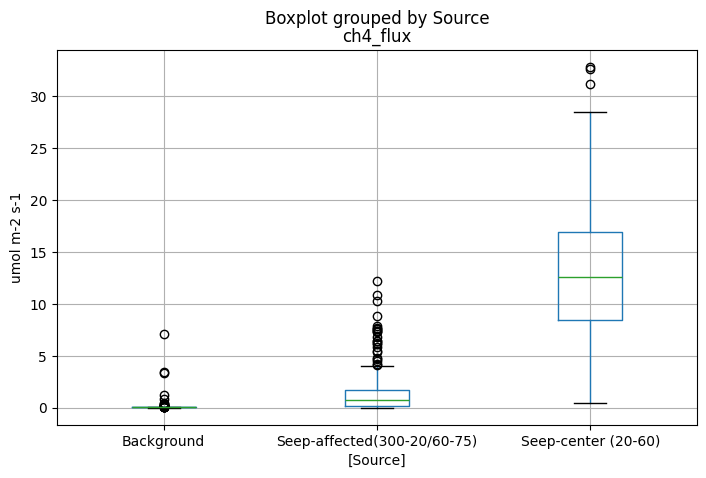

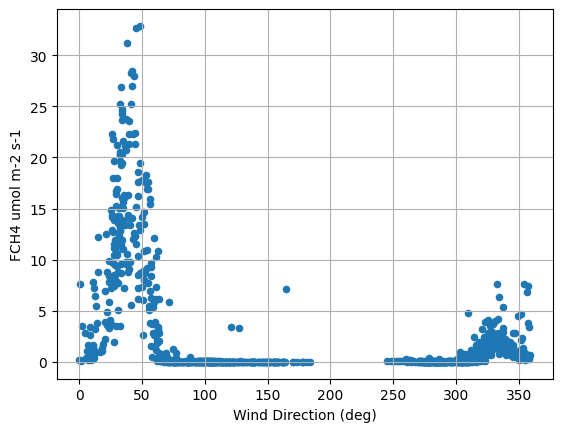

In [181]:

filename = r"D:\data-dump\RDEC1\decompress\out_Test\eddypro_testing_full_output_2026-08-06T113719_exp.csv"
cols = ['wind_dir','wind_speed','u*',
        'H','qc_H','LE','qc_LE','h2o_signal_mean',
        'co2_flux','qc_co2_flux','co2_signal_mean','co2_mixing_ratio',
        'ch4_flux','qc_ch4_flux','ch4_signal_mean','ch4_mole_fraction',
        'x_peak','air_temperature','air_pressure','x_30%','v_var']
cols = [c for c in cols if 'qc' not in c]

kwagrs={
    'ch4_sig':20,
    'irgason_sig':.8,
        'qc_thresh':1,
    'u_thresh':.1,
    'plot':True,
    # 'q_clip':False
}
dfsp = quick_filter(filename,cols,**kwagrs)
dfsp['DOY'] = dfsp.index.dayofyear
dfsp['Hour'] = dfsp.index.hour



dfsp['Source']='Background'
d1,d2=20,60
dfsp.loc[((dfsp['wind_dir']>=d1)&(dfsp['wind_dir']<=d2)),'Source']='Seep-center (20-60)'
d1,d2=0,20
dfsp.loc[((dfsp['wind_dir']>=d1)&(dfsp['wind_dir']<=d2)),'Source']='Seep-affected(300-20/60-75)'
d1,d2=60,75
dfsp.loc[((dfsp['wind_dir']>=d1)&(dfsp['wind_dir']<=d2)),'Source']='Seep-affected(300-20/60-75)'
d1,d2=300,360
dfsp.loc[((dfsp['wind_dir']>=d1)&(dfsp['wind_dir']<=d2)),'Source']='Seep-affected(300-20/60-75)'
print(dfsp['ch4_flux'].count())

for s in dfsp['Source'].unique():
    print(s)
    s = dfsp.loc[dfsp['Source']==s,'ch4_flux'].dropna()
    print(s.mean(),s.std()/s.count()**.5*1.96)

fig,ax=sp(kwargs={'figsize':(8,5)})
# dfsp[]
dfsp[['ch4_flux','Source']].boxplot(by='Source',ax=ax,ylabel='umol m-2 s-1')

# dfsp[['ch4_flux','Source']].groupby('Source').describe().round(3)['ch4_flux'].sort_index(ascending=False)
# ax.set_xticklabels(['Seep-center (20-40)','Seep-adjacent(270-20/60-90)','Background(90-270)'])
dfsp[['ch4_flux','Source']].groupby('Source').describe().round(3)['ch4_flux'].sort_index(ascending=False)


# dfsp[['Source','ch4_spikes','ch4_var']].groupby('Source').describe().round(3).T
fig,ax=sp()
# ax.scatter(dfsp['wind_dir'],dfsp['ch4_flux'])
dfsp.plot(x='wind_dir',y='ch4_flux',kind='scatter',ax=ax,xlabel='Wind Direction (deg)',ylabel='FCH4 umol m-2 s-1',grid=True)

In [182]:
# dfsp_test['mlp_ch4_flux'].describe()
# (dfsp['ch4_flux']*16.01*3600*1e-6).describe()

(dfsp.loc[dfsp['Source']=='Seep-center (20-60)','ch4_flux']*16.01*3600*1e-6).agg(['mean','std','count'])


mean       0.761792
std        0.388232
count    177.000000
Name: ch4_flux, dtype: float64

0.3973420625393208
0.7858144979264018


c:\Users\jskeeter\gsc-permafrost\pyFluxPipeline\.venv\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:781: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(


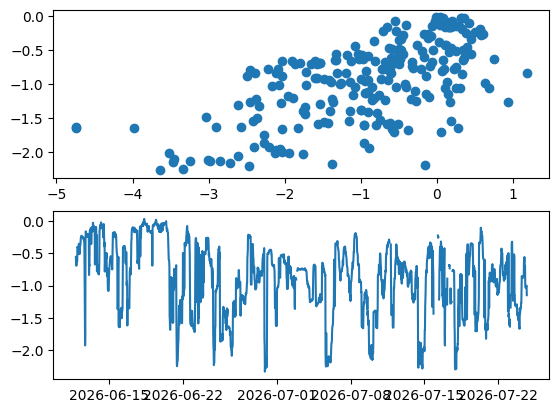

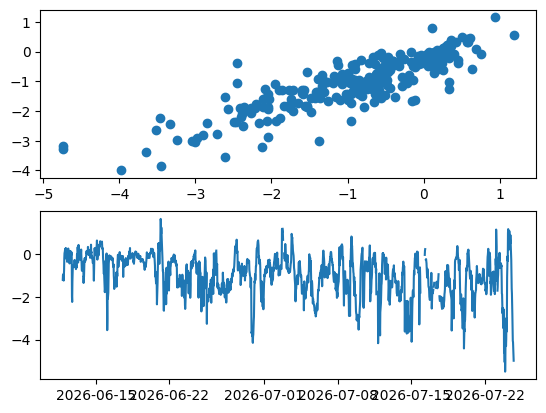

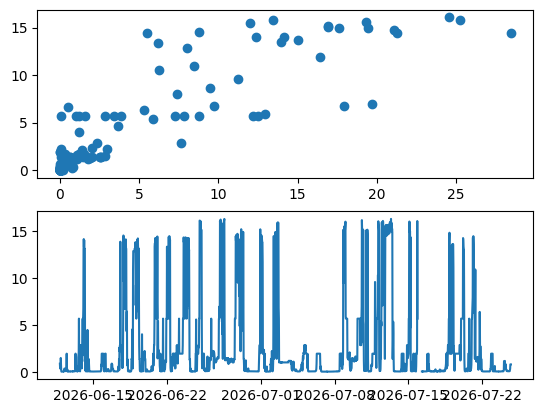

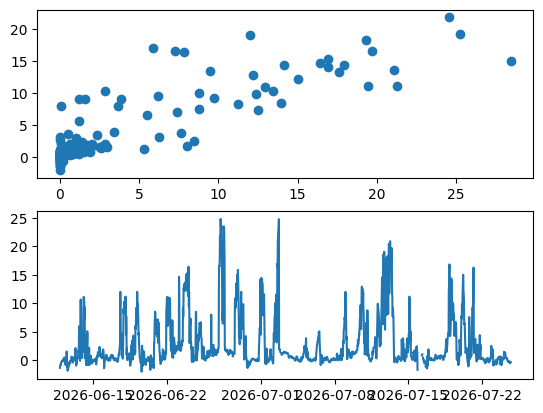

In [156]:
x = ['wind_dir','wind_speed','air_pressure','air_temperature']

dfsp_test = dfsp.copy()
dfsp_test['wind_dir'] = 40

for y in ['co2_flux','ch4_flux']:
    T = dfsp[[y]+x].dropna()
    Y = T[y].copy()
    X = T[x].copy()
    X_train, X_test, y_train, y_test = train_test_split(X, Y, test_size=0.2, random_state=42)

    rf = RandomForestRegressor(min_samples_leaf=30, random_state=0)
    m = rf.fit(X_train, y_train)
    print(m.score(X_test, y_test))
    fig,ax=plt.subplots(2)
    ax[0].scatter(y_test,m.predict(X_test))
    # HR = np.array([[D,H] for D in range(1,366) for H in range(24)])
    dfsp[f"rf_{y}"] = np.nan
    dfsp.loc[dfsp[x].notna().all(axis=1), f"rf_{y}"] = m.predict(dfsp[x].dropna())
    ax[1].plot(dfsp.index,dfsp[f"rf_{y}"])

    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)
    mlp = MLPRegressor(hidden_layer_sizes=(100, 50), activation='relu', max_iter=500, random_state=42)
    mlp.fit(X_train_scaled, y_train)
    mlp.score(X_test_scaled, y_test)

    fig,ax=plt.subplots(2)
    ax[0].scatter(y_test,mlp.predict(X_test_scaled))
    # predictions = mlp.predict(scaler.transform(df[x].dropna()))
    dfsp[f"mlp_{y}"] = np.nan
    dfsp.loc[dfsp[x].notna().all(axis=1), f"mlp_{y}"] = mlp.predict(scaler.transform(dfsp[x].dropna()))
    ax[1].plot(dfsp.index,dfsp[f"mlp_{y}"])
    dfsp_test.loc[dfsp_test[x].notna().all(axis=1), f"mlp_{y}"] = mlp.predict(scaler.transform(dfsp_test[x].dropna()))


In [164]:

dfsp['co2'] = dfsp['co2_flux'].fillna(dfsp[['rf_co2_flux','mlp_co2_flux']].mean(axis=1))* 44.01*1e-6*3600*24#*1e3/3600
dfsp['ch4'] = dfsp['co2_flux'].fillna(dfsp[['rf_ch4_flux','mlp_ch4_flux']].mean(axis=1))* 16.04*1e-6*3600*24#*8#*1e3/3600
mo = [i for i in range(1,13)]
# mo = [4,5,6,7,8,9,10,11]
mx = dfsp.loc[dfsp.index.month.isin(mo),['co2','ch4']].agg(['mean','std','count'])
mx = mx.T
mx['CI'] = 1.96*mx['std']/np.sqrt(mx['count'])
mx = mx.T
# mx = mx[['mean','CI']].T
# mx['co2'] *= 44.01*1e-6*3600*24*365#*1e3/3600
# mx['ch4'] *= 16.04*1e-9*3600*24*365*83#*1e3/3600
vx = df.index[df.index.isin(dfsp.index)]
print(df.loc[vx,['co2','ch4']].mean()/365)
mx
# mx.T['mean']#].diff()
# mx[['co2_flux','ch4_flux']].sum(axis=1)

co2   -4.929675
ch4    0.020223
dtype: float64


,co2,ch4
mean,-3.464536,0.762667
std,3.676295,4.314922
count,2010.000000,2010.000000
CI,0.160719,0.188639


<Axes: >

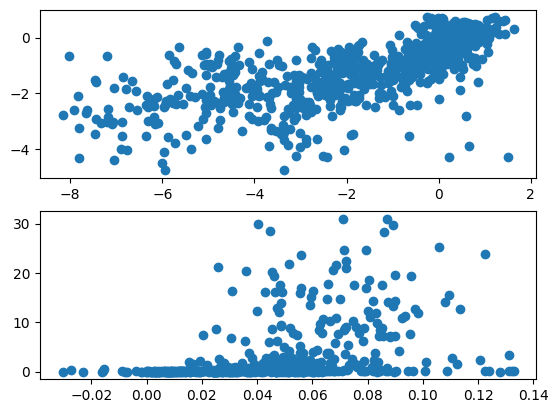

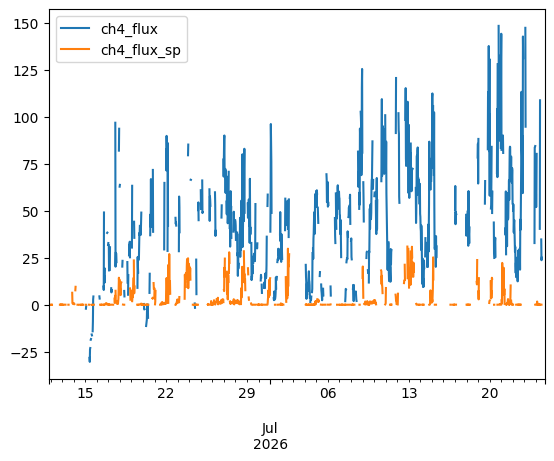

In [ ]:
# df['ch']
# # df.loc[vx].index,dfsp.loc[vx].index
# # df.loc[vx,'ch4_flux'].describe()
# # df['ch4_flux'].describe()
# # dfsp.loc[vx,'ch4_flux'].describe()
# T = df.loc[vx,['co2_flux','ch4_flux']].join(dfsp[['co2_flux','ch4_flux']],rsuffix='_sp')
# fig,ax=plt.subplots(2)
# ax[0].scatter(T['co2_flux'], T['co2_flux_sp'])
# ax[1].scatter(T['ch4_flux']*1e-3, T['ch4_flux_sp'])
# T.corr()**2

# fig,ax=plt.subplots()
# T[['ch4_flux','ch4_flux_sp']].plot(ax=ax)

In [272]:

# X = ['air_pressure']
# fig,ax=sp(x=len(X))
# if len(X) == 1:
#     ax = [ax]
# Seep = dfsp.loc[((dfsp['Source']=='Seep-center')&(dfsp['ch4_flux'].notna())&(dfsp[X].notna().all(axis=1)))]
# print(Seep[X].isna().sum())
# Seep['const'] = 1
# lr = sm.OLS(Seep['ch4_flux'],Seep[X + ['const']])
# results = lr.fit()
# result = lr.fit()
# pred = results.predict(Seep[X + ['const']])
# print(results.summary())
# for i in range(len(X)):
#     Seep.plot(x=X[i],y='ch4_flux',kind='scatter',ax=ax[i])
#     ax[i].plot(Seep[X[i]],pred,color='k')
#     # Seep.plot(x=X[1],y='ch4_flux',kind='scatter',ax=ax[1])
#     ax[i].grid()

# _,ax = sp()
# ax.scatter(Seep['ch4_flux'],results.predict(Seep[X + ['const']]),color='k')
# # Seep.loc[Seep[X]<Seep[X].quantile(.1)].sort_values(by=X)

In [ ]:
plt.figure()
plt.scatter(df[''])

In [459]:


# wbin = 'Wind Sector'
# df[wbin] = pd.cut(df['wd'],bins=[-115,-60,25,55,185],labels=['Background','Pond & Isthmus\nWind Dir: 300 to 25 deg','Seep Plume\nWind Dir: 25 to 55deg','Background'],ordered=False)
# fig,ax=sp(kwargs={'figsize':(8,5)})
# def cr(g,y,X):
#     y = g[y]
#     X = pd.DataFrame({ix:np.array(val) for ix,val in g.items() if ix in X})
#     out = np.nan
#     if len(y)>3:
#         X = sm.add_constant(X)
#         lr = sm.OLS(y,X)
#         result = lr.fit()
#         out = [round(result.rsquared_adj,3),round(result.params[X],2),round(result.params['const'],2),len(y),round(result.f_pvalue,3)]
#         if result.rsquared_adj>.1:
#             print(result.summary())
#             ax.scatter(X[X],y,edgecolor='k',)
#             ax.plot(X[X],result.predict(X),
#                     label = f"{g.name}\nr2={out[0]},n={out[3]},p={out[4]}\ny={out[1]}x+{out[2]}")
#     return(out)

# y = 'ch4_flux'
# X=[X]
# grp = wbin
# gp = df[X+[y,grp]].dropna().groupby(grp).agg(list).T.apply(lambda grp: cr(grp,y=y,X=X)).T.rename(columns={0:'r2',1:'m',2:'b',3:'n',4:'p'})
# ax.grid()
# ax.legend()
# ax.set_title('Air pressure vs methane fluxes at the seep site')
# ax.set_ylabel('FCH4 umol m-2 s-1')
# ax.set_xlabel('Air Pressure (kPa)')
# gp
# # df.index.min(),df.index.max()
# # fig,ax=sp()
# # ax.scatter(df['wind_dir'],df['co2_signal_mean'])

<Axes: xlabel='Wind Direction (deg)', ylabel='FCH4 umol m-2 s-1'>

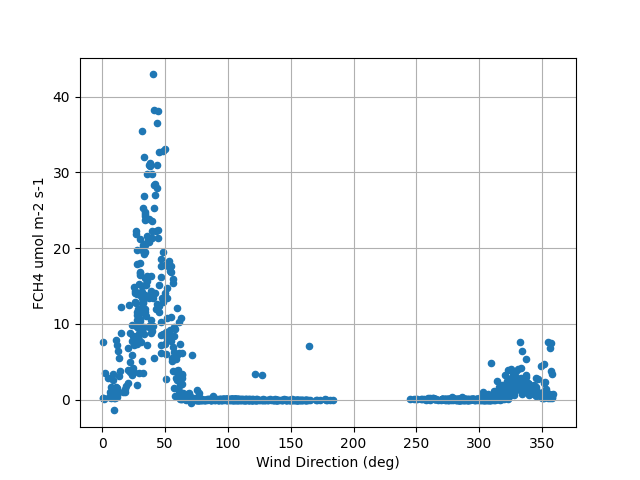

In [ ]:
# df.plot(x='wd',y='ch4_flux',kind='scatter')
# print(df.loc[((df['wd']>100)&(df['ch4_flux']>1)),['ch4_var','ch4_spikes','ch4_flux']])
# ax.set_yscale('symlog')
# df['v_var'].describe()

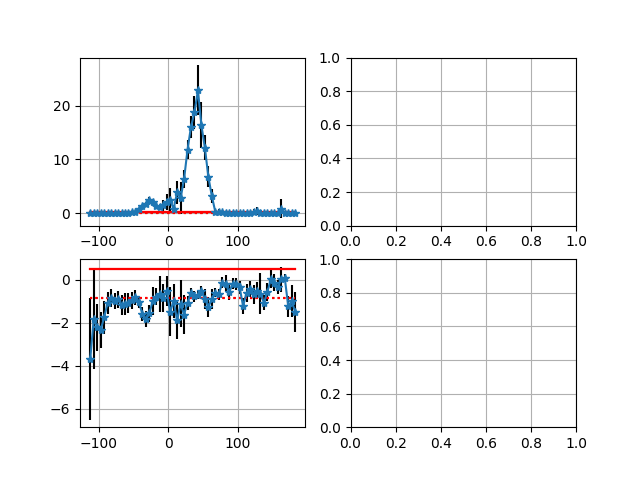

In [441]:
%matplotlib widget
# df['wd'].describe()

by = 5
s = pd.cut(df['wd'],bins=np.arange(-115,185.1,by)).apply(lambda x: x.mid if not type(x) is float else np.nan)
# s = pd.cut(df['wind_dir'],bins=np.arange(0,360.1,by)).apply(lambda x: x.mid)
by = f"by{by}"
s.name = by
gc = df[cols].join(s).groupby(by).agg(['mean','std','count'])
# gc = df.groupby((df['wd']/gscale).round()*gscale).agg(['mean','std','count'])


fig,ax=sp(2,2)
ax = ax.flatten()
ax[0].errorbar(gc.index,gc['ch4_flux']['mean'],yerr=gc['ch4_flux']['std']/gc['ch4_flux']['count']**.5*1.96,marker='*',ecolor='k')
# ax[1].errorbar(gc.index,gc['ch4_mixing_ratio']['mean'],yerr=gc['ch4_mixing_ratio']['std']/gc['ch4_mixing_ratio']['count']**.5*1.96,marker='*',ecolor='k')
for Qcomp,style in zip([.95,1],[':','-']):
    # print(SCL[['ch4_flux','ch4_mixing_ratio']].quantile(Qcomp))
    ax[0].plot(gc.index,gc['ch4_flux']*0+SCL['ch4_flux'].quantile(Qcomp),color='r',linestyle=style)
    # ax[1].plot(gc.index,gc['ch4_mixing_ratio']*0+SCL['ch4_mixing_ratio'].quantile(Qcomp),color='r',linestyle=style)
ax[0].grid()
ax[1].grid()



ax[2].errorbar(gc.index,gc['co2_flux']['mean'],yerr=gc['co2_flux']['std']/gc['co2_flux']['count']**.5*1.96,marker='*',ecolor='k')
# ax[3].errorbar(gc.index,gc['co2_mixing_ratio']['mean'],yerr=gc['co2_mixing_ratio']['std']/gc['co2_mixing_ratio']['count']**.5*1.96,marker='*',ecolor='k')
for Qcomp,style in zip([.25,.75],[':','-']):
    # print(SCL[['co2_flux','co2_mixing_ratio']].quantile(Qcomp))
    ax[2].plot(gc.index,gc['co2_flux']*0+SCL['co2_flux'].quantile(Qcomp),color='r',linestyle=style)
    # ax[3].plot(gc.index,gc['co2_mixing_ratio']*0+SCL['co2_mixing_ratio'].quantile(Qcomp),color='r',linestyle=style)
ax[2].grid()
ax[3].grid()
# fig,ax=plt.subplots()
# ax.scatter(df['co2_mixing_ratio'],df['ch4_mixing_ratio'])

,r2,m,b,n,p
Wind Sector,,,,,
Background,-0.001,0.08,-8.12,478.0,0.57
Pond & Isthmus\nWind Dir: 300 to 25 deg,0.047,0.61,-60.82,304.0,0.00
Seep Plume\nWind Dir: 25 to 55deg,0.098,-3.90,412.70,172.0,0.00


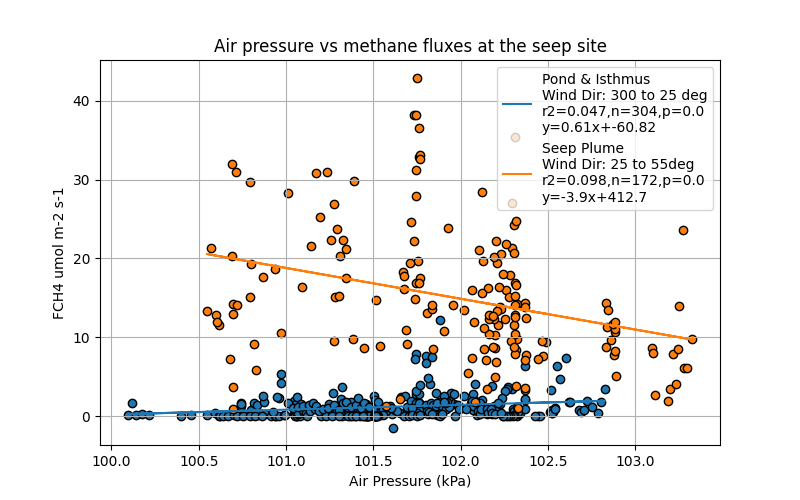